# Comparing the Snowdon Beetle SDMs: Logistic Regression, MaxEnt and Random Forest

*Section 11 — Case study: species distribution modelling, notebook 5 of 5.* Previous: `04_random_forest_species_distribution_modelling`. Next: `12_downloading_data/01_dwnld_usgs_landsat_scenes`.

Notebooks 02–04 modelled the Snowdon beetle with three methods that span the range of SDM approaches: a **logistic regression** (a regression model with terms we chose: one per variable, plus a quadratic temperature term), **MaxEnt** (a regularised point-process model that builds its own features: here quadratic and hinge features) and a **random forest** (a machine-learning ensemble of trees that finds its own response shapes and interactions). All three were fitted to **the same** 23 training presences and 7000 background points, with the same seven variables, tuned with the same spatial cross-validation (1 km blocks, 3 folds) and the same one-standard-error rule, and evaluated on the same 11 test presences and 3000 test background points. So the differences between them come from the models, not from the data.

This notebook asks: how do the three results differ, why, and what do they agree on about the beetle's niche?

**You will learn:**
- how to compare SDMs fairly when their outputs are on different scales (rank-based accuracy measures, rank correlation of the maps, responses scaled to their maximum);
- how to combine models into a consensus map;
- how the structure of each model (fixed terms, features, trees) shapes its responses, its variable importance and its projections.

**Before you start:** run notebooks `01_prepare_datasets` to `04_random_forest_species_distribution_modelling`; this notebook only reads their outputs.

**Data:** `outputs/sdm_LogReg_outs/`, `outputs/sdm_MaxEnt_outs/` and `outputs/sdm_RF_outs/` (test scores, cross-validation scores, response curves, variable importance, scenarios and maps), `outputs/valid_mask.tif` and `outputs/Chrysolina_cerealis_presences.gpkg`.

**Run time:** less than 1 minute.

## Import Modules and Define the Models

In [1]:
import importlib.util
import os

import geopandas
import matplotlib.pyplot as plt
import numpy
import pandas
import rasterio
import rsgispy
import rsgispy.imagecalc.maths
import rsgispy.imageutils.colourtable
import rsgispy.mapping.raster
import rsgispy.modelling.species_distribution as species_distribution
import rsgispy.tools.jsonio

%matplotlib inline
pandas.set_option("display.max_columns", None)
pandas.set_option("display.width", 200)

out_dir = "outputs/sdm_comparison"
os.makedirs(out_dir, exist_ok=True)
valid_msk_img = "outputs/valid_mask.tif"
presences_gdf = geopandas.read_file("outputs/Chrysolina_cerealis_presences.gpkg", layer="presences")

# Name: (output directory, file prefix, plot colour)
models = {
    "Logistic regression": ("outputs/sdm_LogReg_outs", "lr", "tab:blue"),
    "MaxEnt": ("outputs/sdm_MaxEnt_outs", "maxent", "tab:orange"),
    "Random forest": ("outputs/sdm_RF_outs", "rf", "tab:green"),
}
train_gdf = geopandas.read_file("outputs/sdm_LogReg_outs/sdm_train.gpkg", layer="train")
train_pres_gdf = train_gdf[train_gdf["clsid"] == 1]
analysis_vars = [
    "calc_grass_dist", "flush_dist", "impr_grass_dist", "ledges_dist",
    "rock_dist", "scree_dist", "winter_temp",
]

## 1. Accuracy

AUC, TSS (each model at its own maximum-TSS threshold) and the Boyce index depend only on how each model **ranks** the samples, so they can be compared although the three outputs are on different scales (balanced probabilities, cloglog, and the fraction of trees voting presence). The table gathers, for each model: the single model's test scores and its null-model 95th percentile, the test scores of the three-member spatial ensemble, and the mean out-of-fold (spatial cross-validation) scores, with the training AUC of the ensemble members for comparison.

,Logistic regression,MaxEnt,Random forest
test AUC (single),0.964,0.974,0.984
test TSS (single),0.897,0.940,0.937
test Boyce (single),0.940,0.865,0.681
null AUC 95th pct,0.676,0.652,0.641
test AUC (ensemble),0.964,0.976,0.982
test TSS (ensemble),0.908,0.942,0.903
test Boyce (ensemble),0.889,0.896,0.898
train AUC (CV members),0.962,0.960,0.999
spatial CV AUC,0.941,0.939,0.908
spatial CV AUC (sd),0.025,0.012,0.079


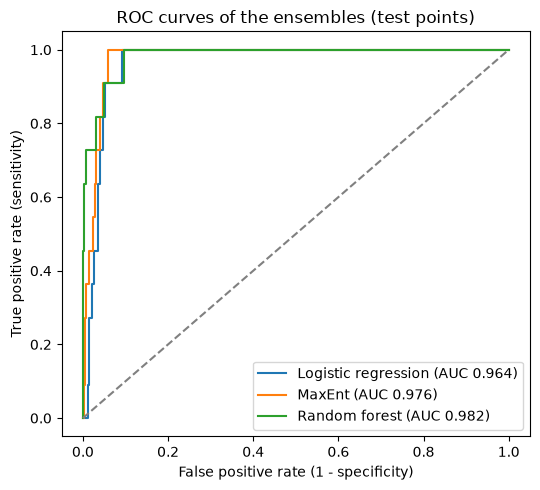

In [2]:
acc_rows = {}
ens_scores = {}
for name, (mdl_dir, prefix, _) in models.items():
    single = rsgispy.tools.jsonio.read_json_to_dict(os.path.join(mdl_dir, f"{prefix}_test_metrics.json"))
    test_df = pandas.read_csv(os.path.join(mdl_dir, f"{prefix}_test_scores.csv"))
    ens_scores[name] = test_df
    ens = species_distribution.calc_sdm_eval_metrics(test_df["clsid"], test_df["ens_prob"], bg_scores="absences")
    cv_df = pandas.read_csv(os.path.join(mdl_dir, f"{prefix}_spatial_cv_scores.csv"))
    acc_rows[name] = {
        "test AUC (single)": single["auc"],
        "test TSS (single)": single["tss"],
        "test Boyce (single)": single["boyce"],
        "null AUC 95th pct": single["null_p95"],
        "test AUC (ensemble)": ens["auc"],
        "test TSS (ensemble)": ens["tss"],
        "test Boyce (ensemble)": ens["boyce"],
        "train AUC (CV members)": cv_df["train_auc"].mean(),
        "spatial CV AUC": cv_df["val_auc"].mean(),
        "spatial CV AUC (sd)": cv_df["val_auc"].std(),
        "spatial CV TSS": cv_df["val_tss"].mean(),
        "spatial CV Boyce": cv_df["val_boyce"].mean(),
    }
acc_df = pandas.DataFrame(acc_rows)
acc_df.to_csv(os.path.join(out_dir, "accuracy_comparison.csv"))

fig, ax = plt.subplots(figsize=(5.5, 5))
for name, test_df in ens_scores.items():
    fpr, tpr, auc = species_distribution.calc_binary_roc_auc(test_df["clsid"], test_df["ens_prob"])
    ax.plot(fpr, tpr, color=models[name][2], label=f"{name} (AUC {auc:.3f})")
ax.plot([0, 1], [0, 1], color="grey", ls="--")
ax.set_xlabel("False positive rate (1 - specificity)")
ax.set_ylabel("True positive rate (sensitivity)")
ax.set_title("ROC curves of the ensembles (test points)")
ax.legend(loc="lower right")
fig.tight_layout()
acc_df.round(3)

**All three models found a real signal.** Every model's test AUC (0.96–0.98) is far above the 95th percentile of its null models (0.64–0.68).

**The test set and the spatial cross-validation rank the models in opposite orders.** On the randomly chosen test points the random forest has the highest AUC (0.984 single, 0.982 ensemble), then MaxEnt, then the logistic regression. In spatial cross-validation, which tests prediction at sites the model has not seen, the order is reversed: logistic regression 0.941 and MaxEnt 0.939, against 0.908 for the random forest, whose scores are also the most variable between folds (sd 0.079). The random forest also has the largest gap between training (0.999) and validation AUC. This is the classic signature of a flexible model with few, clustered presences: it is rewarded for interpolating between nearby training sites, and penalised when it has to transfer.

**Ranking within the suitable area** (Boyce index) is good for all three ensembles on the test points (0.89–0.90), but the single random forest is lower (0.68), and all the out-of-fold Boyce indices are low and unstable (0.27–0.64) with only 5–11 presences per fold.

**The differences are small relative to the uncertainty.** With 11 test presences and three folds, differences of about 0.01–0.02 in AUC are not meaningful. What is robust is the pattern: the two models with constrained, smooth responses (logistic regression and MaxEnt) transfer slightly better to new blocks than the random forest, and MaxEnt has the highest spatial cross-validated TSS and the least variable AUC.

## 2. The Maps

### 2.1 Continuous Suitability

The three maps are on different scales, so we compare them by **rank**: the Spearman correlation between each pair of maps over all the valid pixels.

,Logistic regression,MaxEnt,Random forest
Logistic regression,1.000,0.907,0.718
MaxEnt,0.907,1.000,0.677
Random forest,0.718,0.677,1.000


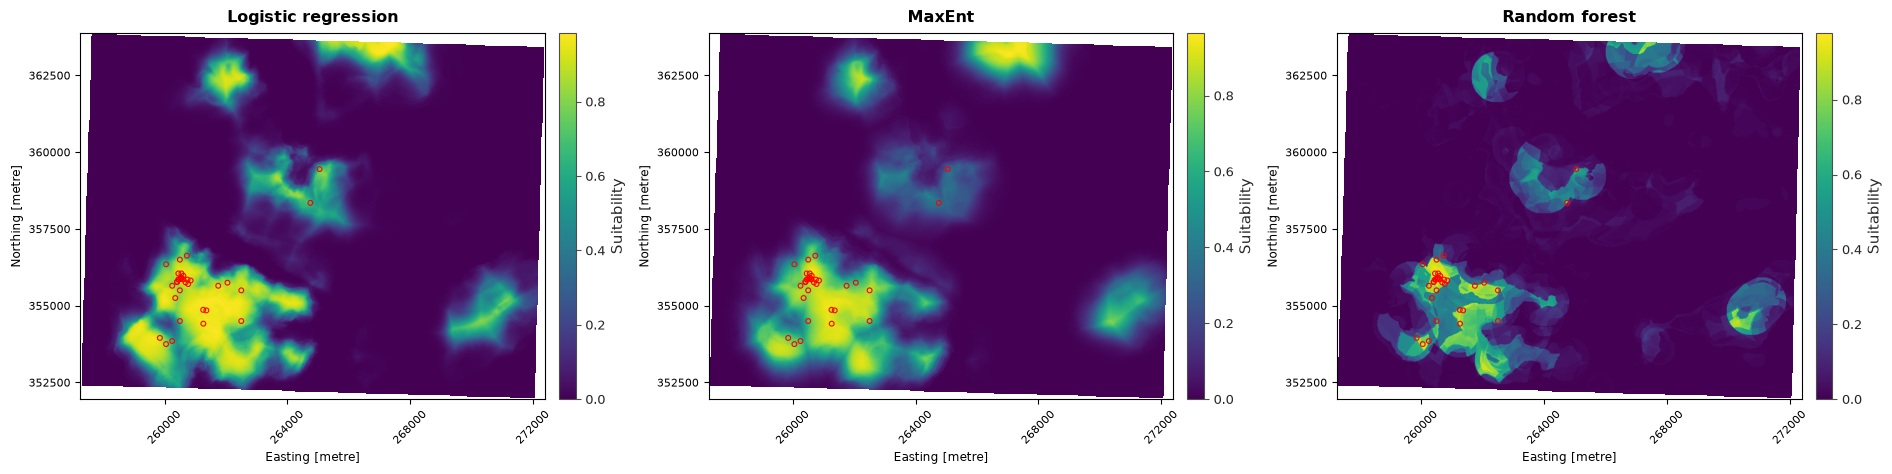

In [3]:
prob_arrs = dict()
for name, (mdl_dir, prefix, _) in models.items():
    with rasterio.open(os.path.join(mdl_dir, f"Snowdon_Beetle_{prefix}_sdm_prob.tif")) as src:
        prob_arrs[name] = src.read(1)
        pxl_km2 = abs(src.res[0] * src.res[1]) / 1e6
valid = numpy.all([arr >= 0 for arr in prob_arrs.values()], axis=0)
rank_corr_df = pandas.DataFrame({name: arr[valid] for name, arr in prob_arrs.items()}).corr(method="spearman")

fig, axs = plt.subplots(1, 3, figsize=(19, 5))
for ax, (name, (mdl_dir, prefix, _)) in zip(axs, models.items()):
    rsgispy.mapping.raster.create_raster_cmap_img_map(
        ax, input_img=os.path.join(mdl_dir, f"Snowdon_Beetle_{prefix}_sdm_prob.tif"), img_band=1,
        title_str=name, show_colour_bar=True, cbar_label="Suitability", show_scale_bar=False,
    )
    presences_gdf.plot(ax=ax, facecolor="none", edgecolor="red", markersize=12, linewidth=0.8)
    ax.tick_params(axis="x", labelrotation=45)
fig.tight_layout()
rank_corr_df.round(3)

The logistic regression and MaxEnt maps are very similar in rank (Spearman r = 0.91): both are smooth functions of the same few variables, with almost the same ledge and temperature responses. The random forest's map is less similar to either (r = 0.72 and 0.68): its step responses produce sharp, often circular edges and patchier suitability, and it ranks the large unsuitable part of the study area differently (the order among low values, which dominate the pixel count, depends on its steps).

### 2.2 Suitable Habitat and a Consensus Map

Each model's map was thresholded at its own maximum-TSS threshold (notebooks 02–04). Adding the three binary maps gives a simple **consensus** (committee) map: the number of models (0–3) that predict each pixel suitable. Combining several models is common practice in SDM: where they agree, the prediction does not depend on the choice of model; where they disagree, it does, and that uncertainty should be reported.

,map,threshold,suitable area (km²)
0,Logistic regression,0.663,15.193
1,MaxEnt,0.684,10.166
2,Random forest,0.240,16.711
3,Consensus: No model,NaN,149.813
4,Consensus: 1 model,NaN,7.340
5,Consensus: 2 models,NaN,4.350
6,Consensus: All 3 models,NaN,8.677


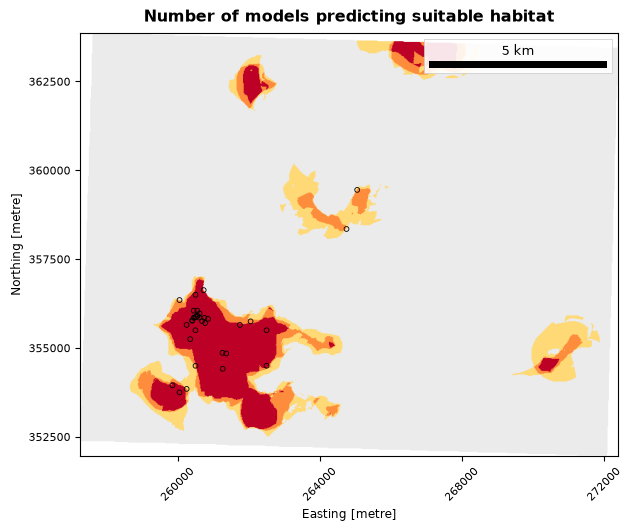

In [4]:
bin_imgs = {
    name: os.path.join(mdl_dir, f"Snowdon_Beetle_{prefix}_sdm_bin.tif")
    for name, (mdl_dir, prefix, _) in models.items()
}
consensus_img = os.path.join(out_dir, "sdm_consensus.tif")
rsgispy.imagecalc.maths.band_maths(
    consensus_img,
    "lr == 255 ? 0 : 1 + lr + mx + rf",
    [rsgispy.imagecalc.maths.BandDefn("lr", bin_imgs["Logistic regression"], 1),
     rsgispy.imagecalc.maths.BandDefn("mx", bin_imgs["MaxEnt"], 1),
     rsgispy.imagecalc.maths.BandDefn("rf", bin_imgs["Random forest"], 1)],
    gdalformat="GTIFF", datatype=rsgispy.TYPE_8UINT, no_data_val=0, use_pbar=False,
)
consensus_classes = {
    1: ("No model", [235, 235, 235]),
    2: ("1 model", [254, 217, 118]),
    3: ("2 models", [253, 141, 60]),
    4: ("All 3 models", [189, 0, 38]),
}
rsgispy.imageutils.colourtable.set_thematic_classes(consensus_img, consensus_classes)

area_rows = []
for name, bin_img in bin_imgs.items():
    with rasterio.open(bin_img) as src:
        bin_arr = src.read(1)
    thres = rsgispy.tools.jsonio.read_json_to_dict(
        os.path.join(models[name][0], f"{models[name][1]}_thresholds.json")
    )["max TSS"]
    area_rows.append({"map": name, "threshold": thres, "suitable area (km²)": (bin_arr == 1).sum() * pxl_km2})
with rasterio.open(consensus_img) as src:
    cons_arr = src.read(1)
for val, (label, _) in consensus_classes.items():
    area_rows.append({"map": f"Consensus: {label}", "suitable area (km²)": (cons_arr == val).sum() * pxl_km2})
area_df = pandas.DataFrame(area_rows)

fig, ax = plt.subplots(figsize=(8, 5.5))
rsgispy.mapping.raster.create_thematic_raster_map(
    ax, input_img=consensus_img, title_str="Number of models predicting suitable habitat"
)
presences_gdf.plot(ax=ax, facecolor="none", edgecolor="black", markersize=12, linewidth=0.6)
ax.tick_params(axis="x", labelrotation=45)
area_df.round(3)

The models predict between 10.2 km² (MaxEnt) and 16.7 km² (random forest) of suitable habitat, 6–10 % of the study area. The differences in area come partly from the models and partly from the thresholds (each chosen on 11 test presences; MaxEnt's 10th percentile training presence threshold, for example, would give 14.4 km²).

All three models agree on 8.7 km², essentially the area around the cluster of records on Yr Wyddfa and the high ground to its south and east. A further 4.4 km² is predicted by two models and 7.3 km² by only one, mostly around the edges of the core and in the northern, central and eastern patches, where there are few or no records. For a conservation application, the core predicted by all three models is the robust result; the fringes and outlying patches are hypotheses, the natural targets of a survey.

## 3. The Responses

Each model's response curve (from notebooks 02–04, with the other variables held at their mean at the training presences) is divided by its own maximum, so the **shapes** can be compared.

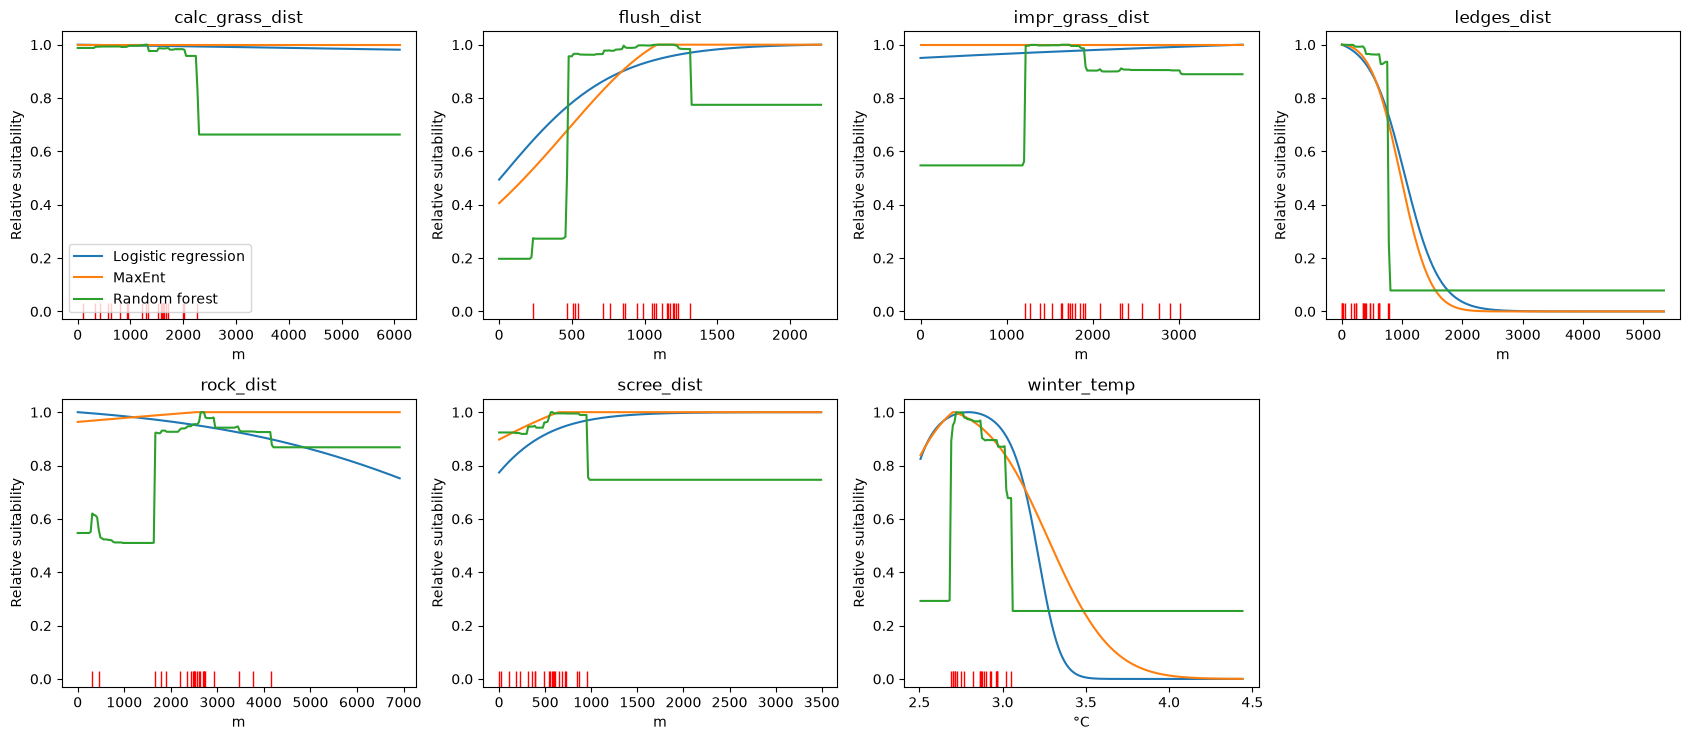

In [5]:
resp_dfs = {
    name: pandas.read_csv(os.path.join(mdl_dir, f"{prefix}_response_curves.csv"))
    for name, (mdl_dir, prefix, _) in models.items()
}
units = {"winter_temp": "°C"}
fig, axs = plt.subplots(2, 4, figsize=(17, 7.5))
for ax, var_name in zip(axs.flatten(), analysis_vars):
    for name, resp_df in resp_dfs.items():
        resp = resp_df[f"{var_name}_resp"]
        ax.plot(resp_df[f"{var_name}_vals"], resp / resp.max(), color=models[name][2], label=name)
    ax.plot(train_pres_gdf[var_name], numpy.zeros(len(train_pres_gdf)), "|", color="red", ms=12)
    ax.set_ylim(-0.03, 1.05)
    ax.set_title(var_name)
    ax.set_xlabel(units.get(var_name, "m"))
    ax.set_ylabel("Relative suitability")
axs[0, 0].legend(loc="lower left")
axs.flatten()[-1].axis("off")
fig.tight_layout()

Where the models agree, the result is robust to the choice of model:

* **Distance to species-rich ledges** — all three put the beetle within about 750–1000 m of a ledge. The logistic regression and MaxEnt decline smoothly over 500–2000 m; the random forest drops abruptly at about 780 m, just beyond the furthest training presence.
* **Winter temperature** — all three have the peak at the cold end (2.7–2.8 °C, roughly 700–750 m in this study area). On the warm side, the logistic regression falls steeply and reaches 0 by about 3.4 °C; MaxEnt falls more gradually; the random forest drops to a floor of about a quarter of its maximum at 3.05 °C (the warmest training presence) and stays there.
* **Distance to flushes** — all three: less suitable close to flushes. Only the random forest also *lowers* suitability beyond 1300 m, again at the edge of the presence data.

Where they disagree, it is because of the models' structure, not the data:

* the logistic regression's terms are fixed in shape (S-curves on the log-odds scale, a parabola for temperature), so it extends every trend smoothly, including the implausible rise away from scree caused by collinearity;
* MaxEnt's hinges let each response level off (flushes beyond about 1 km, scree beyond 640 m, rock beyond 2.5 km) and its L1 penalty removes weak variables completely (improved and calcareous grassland are flat);
* the random forest's steps follow the edges of the presence data in every variable, creating responses such as the drop beyond 2.3 km from calcareous grassland that have no ecological basis.

## 4. Variable Importance

Three views of importance for each model: the jackknife (test AUC with the variable alone, and the drop in test AUC when it is left out), the total-order Sobol index, and the **rank** of the mean |SHAP| value (ranks, because the SHAP values are on different scales: log-odds for the logistic regression, probabilities for the others; for the logistic regression the interventional SHAP values of temperature and its square are added together).

In [6]:
imp_frames = []
for name, (mdl_dir, prefix, _) in models.items():
    metrics = rsgispy.tools.jsonio.read_json_to_dict(os.path.join(mdl_dir, f"{prefix}_test_metrics.json"))
    jk_df = pandas.read_csv(os.path.join(mdl_dir, f"{prefix}_jackknife_var_importance.csv"), index_col=0)
    imp = pandas.DataFrame(
        {
            "AUC alone": jk_df["roc_test_acc_only_var"],
            "AUC drop if left out": metrics["auc"] - jk_df["roc_test_acc_leave_var_out"],
        }
    )
    sobol_csv = os.path.join(mdl_dir, f"{prefix}_sobol_ST.csv")
    if os.path.exists(sobol_csv):
        imp["Sobol ST"] = pandas.read_csv(sobol_csv, index_col=0)["ST"]
    shap_csv = os.path.join(mdl_dir, f"{prefix}_shap_mean_abs.csv")
    if os.path.exists(shap_csv):
        shap_df = pandas.read_csv(shap_csv, index_col=0)
        if prefix == "lr":
            shap_vals = shap_df["interventional"].drop("winter_temp_sq")
            shap_vals["winter_temp"] += shap_df.loc["winter_temp_sq", "interventional"]
        else:
            shap_vals = shap_df["mean_abs_shap"]
        imp["SHAP rank"] = shap_vals.rank(ascending=False)
    imp.columns = pandas.MultiIndex.from_product([[name], imp.columns])
    imp_frames.append(imp)
imp_df = pandas.concat(imp_frames, axis=1).loc[analysis_vars]
imp_df.to_csv(os.path.join(out_dir, "importance_comparison.csv"))
imp_df.round(3)

Logistic regression                                            MaxEnt                                         Random forest                                        
                          AUC alone AUC drop if left out Sobol ST SHAP rank AUC alone AUC drop if left out Sobol ST SHAP rank     AUC alone AUC drop if left out Sobol ST SHAP rank
calc_grass_dist               0.470                0.000    0.000       7.0     0.470                0.000    0.000       6.5         0.494               -0.000    0.055       6.0
flush_dist                    0.889                0.017    0.096       4.0     0.897                0.024    0.071       3.0         0.859                0.008    0.052       3.0
impr_grass_dist               0.737               -0.001    0.001       6.0     0.761                0.000    0.000       6.5         0.738               -0.001    0.045       4.0
ledges_dist                   0.893                0.020    0.633       2.0     0.893                0.020    0.874       1.0         0.830                0.016    0.912       1.0
rock_dist                     0.655               -0.002    0.015       5.0     0.826               -0.000    0.000       5.0         0.646                0.000    0.047       5.0
scree_dist                    0.597                0.004    0.184       3.0     0.597                0.004    0.001       4.0         0.517                0.002    0.011       7.0
winter_temp                   0.859                0.011    0.630       1.0     0.834                0.005    0.536       2.0         0.811                0.001    0.473       2.0

**The models agree on what matters.** In all three, the distance to species-rich ledges and winter temperature have the largest Sobol indices (ledges 0.63–0.91, temperature 0.47–0.63) and the top two SHAP ranks, and the distance to flushes comes third in SHAP for MaxEnt and the random forest. Leaving out ledges or flushes causes the largest drops in test AUC in every model. Calcareous grassland carries no information on its own in any model (AUC alone 0.47–0.49).

**The differences are about how each model handles the weaker and correlated variables:**

* the logistic regression gives scree a large Sobol index (0.18) and the third SHAP rank, the effect of its collinearity with ledges (an artefact, discussed in notebook 02);
* MaxEnt removes improved and calcareous grassland entirely and gives rock no effect in the full model, although rock is informative on its own (AUC 0.83 alone, because a hinge can fit the non-monotonic pattern);
* the random forest spreads small amounts of importance over every variable (Sobol ST 0.01–0.06 for the five weaker ones), because each of them adds a step at the edge of the presence data.

The jackknife "AUC drop if left out" values are all below 0.025 and some are slightly negative: with 11 test presences they mainly show that no single variable other than ledges, flushes and temperature is indispensable.

## 5. Projections to a Warmer Climate

The suitable area under the +0.5 °C and +1 °C scenarios of notebooks 02–04 (each model thresholded at its own current maximum-TSS threshold). Remember that, with this temperature raster, these warmings correspond to large shifts in altitude (notebook 02, section 16), and that 6.6 % and 34 % of the study area are outside the training range in the two scenarios: the projections are a comparison of how the models **extrapolate**, not forecasts.

In [7]:
scen_frames = []
for name, (mdl_dir, prefix, _) in models.items():
    scen_df = pandas.read_csv(os.path.join(mdl_dir, f"{prefix}_scenarios.csv"))
    scen_df.insert(0, "model", name)
    scen_frames.append(scen_df[["model", "warming (°C)", "current (km²)", "scenario (km²)",
                                "stable (km²)", "gained (km²)", "net change (%)"]])
pandas.concat(scen_frames).round(2)

,model,warming (°C),current (km²),scenario (km²),stable (km²),gained (km²),net change (%)
0,Logistic regression,0.5,15.19,2.12,1.74,0.38,-86.02
1,Logistic regression,1.0,15.19,0.00,0.00,0.00,-100.00
0,MaxEnt,0.5,10.17,1.72,1.72,0.00,-83.13
1,MaxEnt,1.0,10.17,0.00,0.00,0.00,-100.00
0,Random forest,0.5,16.71,5.95,5.77,0.19,-64.38
1,Random forest,1.0,16.71,5.34,5.34,0.00,-68.03


The logistic regression and MaxEnt agree closely: about 85 % of the suitable area is lost at +0.5 °C, remaining only on the highest ground, and none remains at +1 °C. The random forest loses less (−64 % and −68 %) and keeps about 5 km² even at +1 °C.

The difference is entirely due to how the models treat temperatures warmer than those of the presences. The logistic regression's parabola and MaxEnt's quadratic feature keep falling, so warmer means less suitable. The random forest's temperature response drops to a constant at the warmest presence (3.05 °C), so beyond that it cannot tell 3.1 °C from 4.4 °C: pixels next to ledges keep the same suitability, just above its low threshold, however warm they become. Neither behaviour is "correct": the data contain no presences warmer than 3.05 °C, so the projections differ in **assumptions**, not in evidence. This is why projections should be made with several models, reported with their disagreement, and accompanied by MESS/ExDet maps showing where they extrapolate.

## 6. Summary: Why Do the Models Differ, and What Do They Agree On?

**What the three models agree on: the beetle's niche.** With the same data, three very different methods describe the same niche: the Snowdon beetle is found **within about 1 km of upland species-rich ledges**, in a **narrow, cool band of winter temperature** at the cold end of the study area (about 2.5–3.2 °C, i.e. roughly 500–850 m, close to the 555–827 m of the NRW surveys), and **away from wet flushes**. Improved grassland, scree, rock and calcareous grassland add little once these are known. Because the three models agree, these conclusions do not depend on the choice of model; their limits come from the data (34 presences from a few crags, proxies for thyme and grazing, temperature confounded with altitude), as discussed in notebook 02.

**Why the results differ.** The data were identical, so the differences come from each model's assumptions about the **shape** of the responses:

| | Logistic regression | MaxEnt | Random forest |
| --- | --- | --- | --- |
| Response shapes | Chosen by us: S-curves, plus a parabola for temperature | Built from features (here quadratic and hinge), regularised | Learnt freely: steps |
| Weak variables | Kept, with small coefficients (L1 can remove them) | Removed by the L1 penalty | Each used a little |
| Collinearity | Can produce implausible signs (scree) | Reduced by the penalty | Absorbed (importance shared) |
| Fit to the training sites | Smooth | Smooth | Close (training AUC 0.999), envelope around the presences |
| Spatial CV AUC | 0.94 | 0.94 | 0.91, most variable |
| Beyond the training range | Extrapolates the trends (parabola keeps falling) | Clamps the variables, but the quadratic still falls within the range | Flat (constant at the last step) |
| Output | Relative suitability (balanced classes) | Cloglog | Fraction of trees (balanced classes) |

**Which should you use?**

* With **few, clustered presences**, as here, the more constrained models (logistic regression with carefully chosen terms, or MaxEnt with moderate regularisation) transfer better to unsampled sites and give smoother, more interpretable responses. MaxEnt has the advantage of choosing its own response shapes, with less hand-crafting (we had to add the quadratic temperature term to the logistic regression ourselves), and it is designed for presence–background data.
* A **random forest** comes into its own with many presences, many variables and genuine interactions; with 23 training presences it mostly learns an envelope around them. If you use one, tune it with spatial cross-validation, check more than one accuracy measure, and never set its threshold from its training predictions.
* For **projections** to other conditions, model choice changes the answer wherever the model extrapolates, so use several models and report where they disagree, together with MESS/ExDet.

**Using them together.** Fitting several models and combining them, as in the consensus map of section 2.2 (or by averaging their rank-transformed predictions), is common practice in SDM (e.g. "ensemble forecasting", Araújo & New 2007). The areas where all the models agree are robust to the choice of model; the areas where they disagree show the uncertainty that comes from that choice, and they deserve to be reported, not hidden.

**Going further:** try the other options of the guide (bias grids if target-group records are available, `thin_pts_min_dist` to thin the presences further, `SpatialBufferCV` or `nested_spatial_cv`), add the habitats hidden in Phase 1 mosaics (notebook 01), or repeat the comparison with the stricter record filters of notebook 01 and see which conclusions survive.